# Heart disease (UCI)

# 1. Exploratory Data Analysis

## Objectif :
- Comprendre du mieux possible nos données
- Développer une premiere stratégie de modélisation

## Checklist de base
#### Analyse de Forme :
- **variable target** :
Elle représente le diagnostic de maladie coronarienne par angiographie.
    
    - **0** : pas de maladie (rétrécissement des artères inférieur à 50 %).
    - **1 à 4** : maladie présente, avec un degré de sévérité croissant.


- **lignes et colonnes** : le dataset contient 920 observations et 16 variables.
- **types de variables** : il y a des variables catégorielles et numériques.
- **Analyse des valeurs manquantes** : la plupart des variables ne contiennent pas de variables manquantes. Celles qui en contiennent sont les suivantes, avec leur taux de valaurs manquantes associé :
  - trestbps                     6.521739
  - chol                        21.956522
  - fbs                          9.782609
  - thalch                       5.978261
  - exang                        5.978261
  - oldpeak                      6.739130


#### Analyse de Fond :
- **Visualisation de la target** :

    On observe qu'on n'a pas le même nombre d'observations pour toutes les catégories. Il n'y a que les catégories 2 et 3 qui ont à peu près le même nombre d'observations (11% des observations). La catégorie majoritaire est 0, avec 44% des observations, et celle minoritaire est 4, avec 3% des observations. La catégorie 1 représente 28% des observations.

    
    
- **Signification des variables** :

    - Pression artérielle systolique au repos (mm Hg) - trestbps :
    on observe que les outliers se situent au dessus de 170 mmHg environ et en-dessous de 80 mmHg environ. La valeur la plus fréquente est autours de 120 mmHg

    - Cholestérol sérique total (mg/dL) - chol :
    on observe que les outliers se situent au dessus de 390 mg/dL environ et en-dessous de 100 mg/dL environ. La valeur la plus fréquente se situe aux alentours de 240 mg/dL

    - Fréquence cardiaque maximale atteinte (bpm) - thalch :
    les outliers se situent en-dessous de 70 bpm et il y en a que deux. Dans le graphe de densité, on peut observer deux pics, un à 120bpm et un autre à 150 bpm (deux sous population ? malade vs pas malade ?).

    - Sous-décalage (dépression) du segment ST à l’effort par rapport au repos (en mm) :
    Les outliers se situent au dessus de 4mm et en-dessous de -2mm. La valeur la plus fréquente est de 0mm mais on a un large pic qui s'étale entre 0.8 et 2 mm (deux sous-populations ?)

    - Nombre de gros vaisseaux coronaires (ca) :
    On observe que la valeur la plus fréquente est 0 et on a un outlier à 3.

    - Dans ce dataset, on observe que plus de 75% des individus sont des hommes.
    - Il n'y a pas le même nombre d'observations d'un hôpital à l'autre.
    - Plus de la moitié des patients ne présentent pas de douleur toracique (**cp**).
    - Plus de 75% des patients n'ont pas une glycémie à jeun (**fbs**)supérieure à 120mg/dl.
    - Environ 55% des patients ont un electrocardiogramme au repos normal, n'ont pas d'angine déclanchée par l'effort et ont une pente du segment ST normale.
    - Pour la plupart des individus (~ 45%), la valeur de la fréquence cardiaque maximale est 'reversable defect', ce qui signifie qu'à l'effort le coeur est mal irrigué par le sang.

- **Relation Variables / Target** :

    - On observe une différence significative entre les malades et pas malades dans le graphe de densité pour la variable **thalach** (fréquence cardiaque maximale). La distribution des malades présente un pic à 120 bpm tandis que celle des non malades présente un pic à 160 bpm.
    - La variable **oldpeak** (sous-décalage du segment ST) présente aussi une distribution différente entre les malades et ceux qui ne le sont pas. En effet, on peut observer que le pic qui s'étale entre 1 et 2.5 est beaucoup plus important pour les malades que pour les non malades, contrairement au pic à 0.
    - Pour la variable **ca** (nombre de gros vaisseaux coronaires), on observe une différence significative entre les individus malades et pas malade au niveau de la valeurs 0: le nombre de personne saine n'ayant pas de gros vaisseaux coronaire est supérieur à celui des personnes malades.
    - **sex** :
    On observe que chez les femmes 74% des individus ne sont pas malades tandis que chez les hommes 63% sont malades.
    - **Hôpital**: Il ya 4 catégories. On observe que les cohortes issues de la Suisse et VA Long Beach sont celles qui contiennent le moins de patients sains (6.5% et 25.5% respectivement).
    - **type de douleur toracique** (vp): Il y a 4 catégories. 78% des personnes asymptomatiques sont malades et 86% des personnes dans la catégorie atypical angina  ne sont pas malade.
    - **glycémie à jeun** (fbs): Il y a 2 catégories. 68% des personnes ayant une glycémie à jeun supérieure à 120mg/dL sont malades.
    - **Electrocardiogramme au repos** - restecg :
    Il y a 3 catégories. La catégorie où l'on observe une différence importante entre les malades et non malades est st-t abnormality : 65% des personnes dans cette catégorie sont malades.
    -  **angine déclanchée à l'effort** - exang :
    Il y a 2 catégories. On observe que 63% des individus qui n'ont pas d'angine déclanchée à l'effort ne sont pas malades et 83% des personnes ayant une angine déclanchée à l'effort sont malades
    -  **pente du segment ST au pic de l’effort** - slope:
    Il y a 3 catégories. La différence plus importante entre les malades et les non malades s'observe pour les catégorie downsloping et flat slope: pour ces deux catégories, 77% des individus sont malades.
    - **résultat d’une scintigraphie myocardique au thallium, qui montre l’irrigation du muscle cardiaque** - thal :
    Il y a 3 catégories. Pour chacune de ces catégories on observe une différence significative entre le pourcentage des personnes malades et celui des personnes pas malades :
      - normal: 70% ne sont pas malades
      - fixed defect : 76% sont malades
      - reversable defect : 80% sont malades

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
from google.colab import drive
drive.mount('/content/gdrive')

Mounted at /content/gdrive


In [ ]:
data = pd.read_csv("/content/gdrive/MyDrive/heart_disease_project/heart_disease_uci.csv", sep = ",")
with pd.option_context("display.max_rows", None, "display.max_columns", None):
    print(data)

      id  age     sex        dataset               cp  trestbps   chol    fbs  \
0      1   63    Male      Cleveland   typical angina     145.0  233.0   True   
1      2   67    Male      Cleveland     asymptomatic     160.0  286.0  False   
2      3   67    Male      Cleveland     asymptomatic     120.0  229.0  False   
3      4   37    Male      Cleveland      non-anginal     130.0  250.0  False   
4      5   41  Female      Cleveland  atypical angina     130.0  204.0  False   
5      6   56    Male      Cleveland  atypical angina     120.0  236.0  False   
6      7   62  Female      Cleveland     asymptomatic     140.0  268.0  False   
7      8   57  Female      Cleveland     asymptomatic     120.0  354.0  False   
8      9   63    Male      Cleveland     asymptomatic     130.0  254.0  False   
9     10   53    Male      Cleveland     asymptomatic     140.0  203.0   True   
10    11   57    Male      Cleveland     asymptomatic     140.0  192.0  False   
11    12   56  Female      C

In [ ]:
shape = data.shape
print(f"Le dataset contient {shape[0]} observations et {shape[1]} variables.")

Le dataset contient 920 observations et 16 variables.


In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        920 non-null    int64  
 1   age       920 non-null    int64  
 2   sex       920 non-null    object 
 3   dataset   920 non-null    object 
 4   cp        920 non-null    object 
 5   trestbps  861 non-null    float64
 6   chol      890 non-null    float64
 7   fbs       830 non-null    object 
 8   restecg   918 non-null    object 
 9   thalch    865 non-null    float64
 10  exang     865 non-null    object 
 11  oldpeak   858 non-null    float64
 12  slope     611 non-null    object 
 13  ca        309 non-null    float64
 14  thal      434 non-null    object 
 15  num       920 non-null    int64  
dtypes: float64(5), int64(3), object(8)
memory usage: 115.1+ KB


Transformons les variables catégorielles afin de pouvoir les exploiter.

In [ ]:
#data["sex"] = data["sex"].map({"Male": 1, "Female": 0})
#data["fbs"] = data["fbs"].map({True: 1, False: 0})
#data["exang"] = data["exang"].map({True: 1, False: 0})
data2 =  data.copy()
data2[["sex", "fbs", "exang", "dataset", "cp", "restecg", "slope", "thal"]] = data2[["sex", "fbs", "exang", "dataset", "cp", "restecg", "slope", "thal"]].astype("category")
data = pd.get_dummies(data, columns = ["sex", "fbs", "exang", "dataset", "cp", "restecg", "slope", "thal"], drop_first = True, dtype = int)

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   id                        920 non-null    int64  
 1   age                       920 non-null    int64  
 2   trestbps                  861 non-null    float64
 3   chol                      890 non-null    float64
 4   thalch                    865 non-null    float64
 5   oldpeak                   858 non-null    float64
 6   ca                        309 non-null    float64
 7   num                       920 non-null    int64  
 8   sex_Male                  920 non-null    int64  
 9   fbs_True                  920 non-null    int64  
 10  exang_True                920 non-null    int64  
 11  dataset_Hungary           920 non-null    int64  
 12  dataset_Switzerland       920 non-null    int64  
 13  dataset_VA Long Beach     920 non-null    int64  
 14  cp_atypica

In [ ]:
print(data.columns)

Index(['id', 'age', 'trestbps', 'chol', 'thalch', 'oldpeak', 'ca', 'num',
       'sex_Male', 'fbs_True', 'exang_True', 'dataset_Hungary',
       'dataset_Switzerland', 'dataset_VA Long Beach', 'cp_atypical angina',
       'cp_non-anginal', 'cp_typical angina', 'restecg_normal',
       'restecg_st-t abnormality', 'slope_flat', 'slope_upsloping',
       'thal_normal', 'thal_reversable defect'],
      dtype='object')


Pour certaines variables, les valeurs manquantes sont encodées par des 0. Nous tranformons donc ces 0 en NaN pour ensuite pourvoir calculer le nombre de valeurs absentes.

In [ ]:
data["chol"] = data["chol"].replace(0, np.nan)
data["trestbps"] = data["trestbps"].replace(0, np.nan)

In [ ]:
print(data.head())

   id  age  trestbps   chol  thalch  oldpeak   ca  num  sex_Male  fbs_True  \
0   1   63     145.0  233.0   150.0      2.3  0.0    0         1         1   
1   2   67     160.0  286.0   108.0      1.5  3.0    2         1         0   
2   3   67     120.0  229.0   129.0      2.6  2.0    1         1         0   
3   4   37     130.0  250.0   187.0      3.5  0.0    0         1         0   
4   5   41     130.0  204.0   172.0      1.4  0.0    0         0         0   

   ...  dataset_VA Long Beach  cp_atypical angina  cp_non-anginal  \
0  ...                      0                   0               0   
1  ...                      0                   0               0   
2  ...                      0                   0               0   
3  ...                      0                   0               1   
4  ...                      0                   1               0   

   cp_typical angina  restecg_normal  restecg_st-t abnormality  slope_flat  \
0                  1               0  

In [ ]:
data2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   id        920 non-null    int64   
 1   age       920 non-null    int64   
 2   sex       920 non-null    category
 3   dataset   920 non-null    category
 4   cp        920 non-null    category
 5   trestbps  861 non-null    float64 
 6   chol      890 non-null    float64 
 7   fbs       830 non-null    category
 8   restecg   918 non-null    category
 9   thalch    865 non-null    float64 
 10  exang     865 non-null    category
 11  oldpeak   858 non-null    float64 
 12  slope     611 non-null    category
 13  ca        309 non-null    float64 
 14  thal      434 non-null    category
 15  num       920 non-null    int64   
dtypes: category(8), float64(5), int64(3)
memory usage: 65.9 KB


On peut observer que les variables trestbps, chol, fbs, restecg, thalch, exang, oldpeak, slope, ca et thal présentent des valeurs manquantes. Regardons la proportions de variables manquantes dans chacunes de ces variables.  

In [ ]:
pourcentage = (data.isnull().mean())*100
print(pourcentage)

id                           0.000000
age                          0.000000
trestbps                     6.521739
chol                        21.956522
thalch                       5.978261
oldpeak                      6.739130
ca                          66.413043
num                          0.000000
sex_Male                     0.000000
fbs_True                     0.000000
exang_True                   0.000000
dataset_Hungary              0.000000
dataset_Switzerland          0.000000
dataset_VA Long Beach        0.000000
cp_atypical angina           0.000000
cp_non-anginal               0.000000
cp_typical angina            0.000000
restecg_normal               0.000000
restecg_st-t abnormality     0.000000
slope_flat                   0.000000
slope_upsloping              0.000000
thal_normal                  0.000000
thal_reversable defect       0.000000
dtype: float64


In [ ]:
print(data.columns)

Index(['id', 'age', 'trestbps', 'chol', 'thalch', 'oldpeak', 'ca', 'num',
       'sex_Male', 'fbs_True', 'exang_True', 'dataset_Hungary',
       'dataset_Switzerland', 'dataset_VA Long Beach', 'cp_atypical angina',
       'cp_non-anginal', 'cp_typical angina', 'restecg_normal',
       'restecg_st-t abnormality', 'slope_flat', 'slope_upsloping',
       'thal_normal', 'thal_reversable defect'],
      dtype='object')


In [ ]:
var_num = [col for col in data2.select_dtypes("float")]
(data[var_num]).describe()

,trestbps,chol,thalch,oldpeak,ca
count,860.000000,718.000000,865.000000,858.000000,309.000000
mean,132.286047,246.832869,137.545665,0.878788,0.676375
std,18.536175,58.527062,25.926276,1.091226,0.935653
min,80.000000,85.000000,60.000000,-2.600000,0.000000
25%,120.000000,210.000000,120.000000,0.000000,0.000000
50%,130.000000,239.500000,140.000000,0.500000,0.000000
75%,140.000000,276.750000,157.000000,1.500000,1.000000
max,200.000000,603.000000,202.000000,6.200000,3.000000


- La variable "âge" ne présente pas de valeur abérrante car les valeurs sont comprises entre 28 et 77 ans.
- La valeur de la pression artérielle systolique au repos (**trestbps**) chez l'adulte est entre 90 et 120 mmHg, tandis que dans le dataset la moyenne est de 132 mmHg, ce qui signifie qu'il y a des individus qui ont une pression systolique au repos supérieure à la normale, ce qui augmente la moyenne générale. On peut observer que la valeur maximale est de 200 mmHg, ce qui correspond à une hypertension de degré 3. Ceci peut exister donc cette valeur ne correspond pas forcément à une valeur fausse, bien qu'elle soit atypique. La valeur minimale est de 80mmHg, ce qui correspond à une valeur normale pour des personnes jeunes, minces, les femmes enceintes ou les athlètes d'endurance très entraînés.
- Le taux de cholestérol sérique total normal chez l'adulte est inférieur à 200 mg/dL, tandis que dans notre dataset la moyenne est à 246mg/dL. Ceci signifie qu'il y a des individus avec un taux de cholestérol sérique plus élevé que la normale, ce qui augmente la moyenne. Mais on peut aussi remarquer que la valeur minimale est de 85mg/dL. Cette valeur peut exister et n'est pas forcément liée à une erreur de saisie, bien qu'elle soit atypique.
- La fréquence cardiaque maximale (**thalach**) se situe généralement entre 150 et 200 bpm chez l'adulte. On remarque que la moyenne est de 137bpm, ce qui est inférieur à la normale. On observe également que la valeur maximale est de 202bpm et que la valeur minimale est de 60bpm. La valeur maximale n'est donc pas abérrante. Par contre une valeur de 60bpm est probablement dûe à une erreur de saisie car elle est physiologiquement impossible. On observe que la médiane est à 140bpm, ce qui signifie que 50% des valeurs sont inférieures à 140bpm, et donc inférieures à la normale.

On remarque qu'on a pas le même nombre d'observations pour chaque âge. En effet, il y a des âges pour lesquelles on a qu'une seule observation et d'autres pour lesquelles on en a quelque dizaine. Donc la moyenne de la fréquence cardiaque maximale pour chaque âge n'est pas informative pour les âges qui possèdent peu d'observations. On décide donc de découper les âges par tranches.

En affichant seulement le boxplot de la fréquence cardiaque, on observe en revanche que les outlier se situent entre 60 et 65 bpm.

On peut observer qu'il y a deux pics : un à 125bpm et un autre à environ 150 bpm. Il y a deux pics, ce qui signale probablement la présence de deux populations (malade vs pas malade ?).

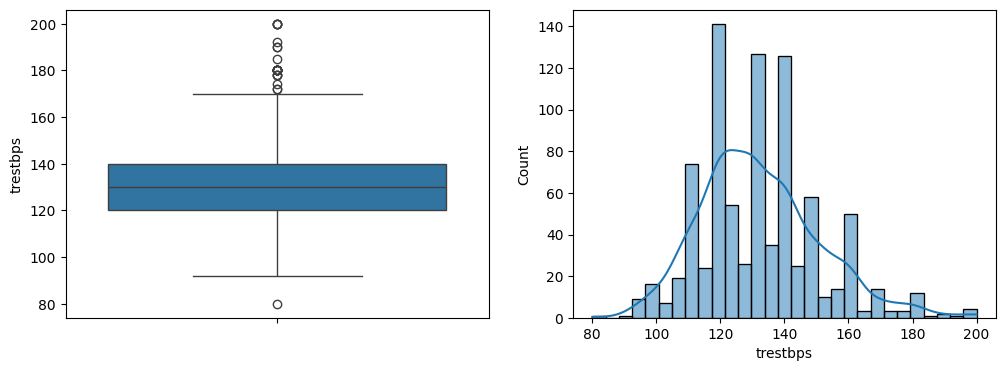

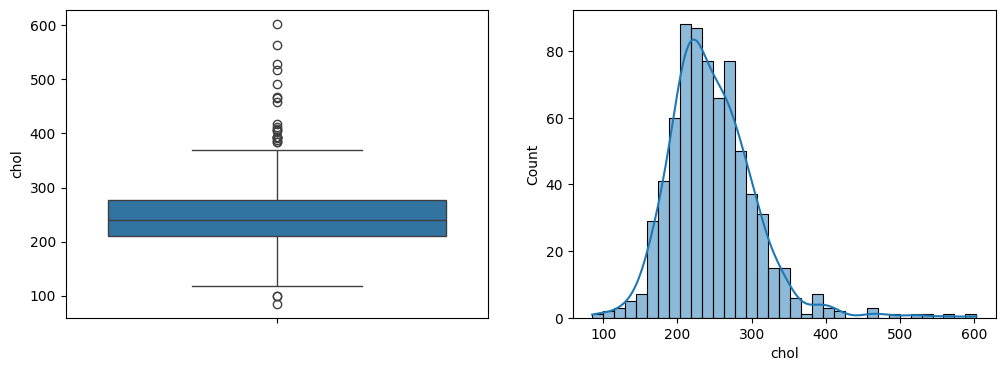

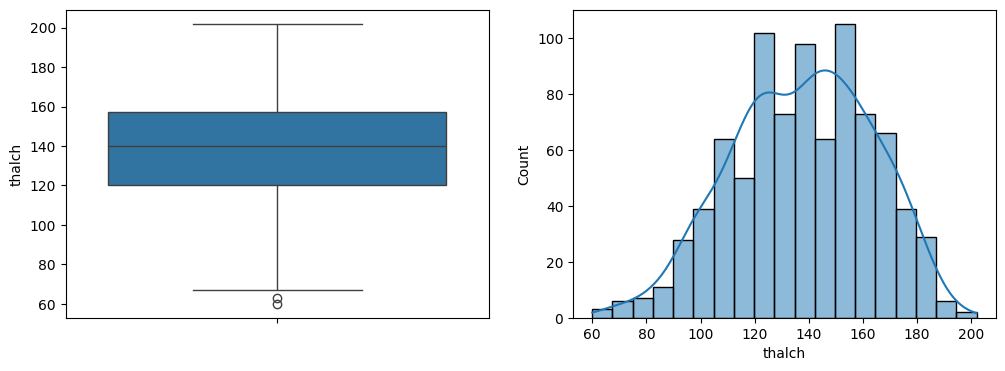

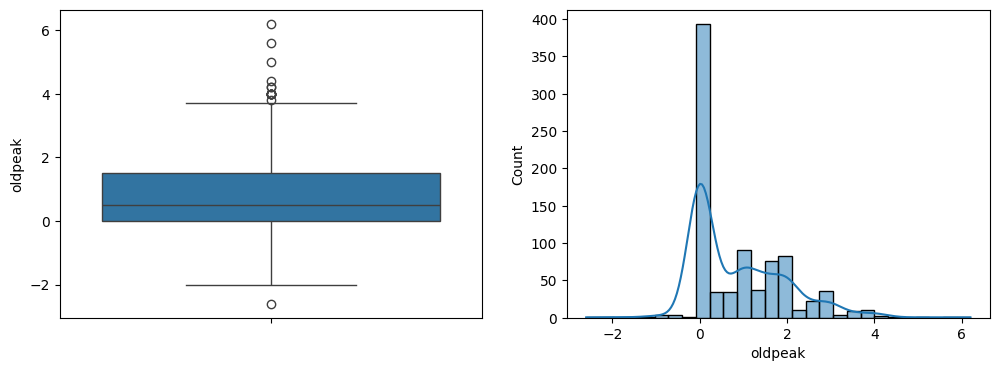

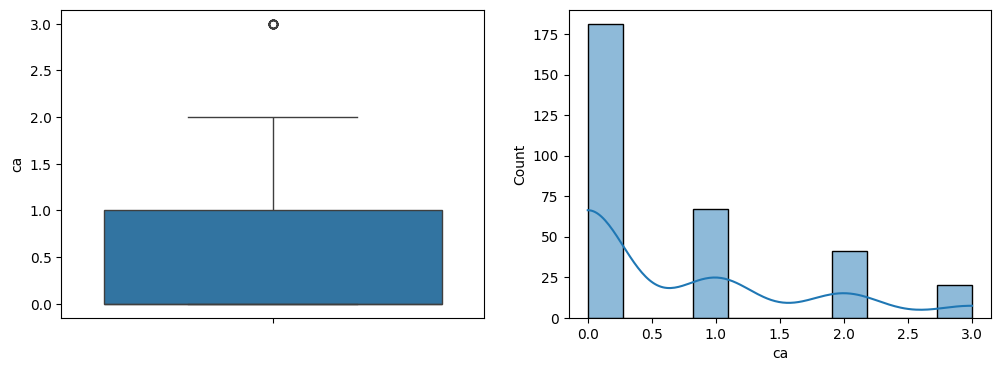

In [ ]:
for col in data.select_dtypes('float').columns:
  fig, axes = plt.subplots(1,2, figsize = (12,4))
  sns.boxplot(data[col], ax = axes[0])
  sns.histplot(data[col], ax = axes[1], kde = True)


- Pression artérielle systolique au repos (mm Hg) - trestbps :
on observe que les outliers se situent au dessus de 170 mmHg environ eet en dessous de 80 mmHg environ. La valeur la plus fréquente est autours de 120 mmHg

- Cholestérol sérique total (mg/dL) - chol :
on observe que les outliers se situent au dessus de 390 mg/dL environ et en dessous de 100 mg/dL environ. La valeur la plus fréquente se situe aux alentours de 240 mg/dL

- Fréquence cardiaque maximale atteinte (bpm) - thalch :
les outliers se situent en dessous de 70 bpm et il y en a que deux. Dans le graphe de densité, on peut observer deux pics, un à 120bpm et un autre à 150 bpm (deux sous population ? malade vs pas malade ?).

- Sous-décalage (dépression) du segment ST à l’effort par rapport au repos (en mm) :
Les outliers se situent au dessus de 4mm et en dessous de -2mm. La valeur la plus fréquente est de 0mm mais on a un large pic qui s'étale entre 0.8 et 2 mm (deux ous-populations ?)

- Nombre de gros vaisseaux coronaires (ca) :
On observe que la valeur la plus fréquente est 0 et on a un outlier à 3.

In [ ]:
data["num"].value_counts(normalize = True).sort_index()*100

,proportion
num,
0,44.673913
1,28.804348
2,11.847826
3,11.630435
4,3.043478


On observe qu'on n'a pas le même nombre d'observations pour toutes les catégories. Il n'y a que les catégories 2 et 3 qui ont à peu près le même nombre d'observations.

In [ ]:
for col in data2.select_dtypes("category").columns:
  print(f"{col:-<50}{data2[col].unique()}")

sex-----------------------------------------------['Male', 'Female']
Categories (2, object): ['Female', 'Male']
dataset-------------------------------------------['Cleveland', 'Hungary', 'Switzerland', 'VA Long Beach']
Categories (4, object): ['Cleveland', 'Hungary', 'Switzerland', 'VA Long Beach']
cp------------------------------------------------['typical angina', 'asymptomatic', 'non-anginal', 'atypical angina']
Categories (4, object): ['asymptomatic', 'atypical angina', 'non-anginal', 'typical angina']
fbs-----------------------------------------------[True, False, NaN]
Categories (2, bool): [False, True]
restecg-------------------------------------------['lv hypertrophy', 'normal', 'st-t abnormality', NaN]
Categories (3, object): ['lv hypertrophy', 'normal', 'st-t abnormality']
exang---------------------------------------------[False, True, NaN]
Categories (2, bool): [False, True]
slope---------------------------------------------['downsloping', 'flat', 'upsloping', NaN]
Categorie

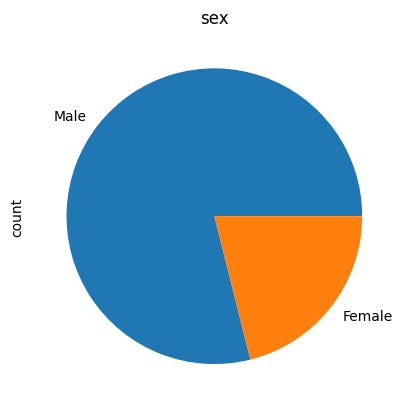

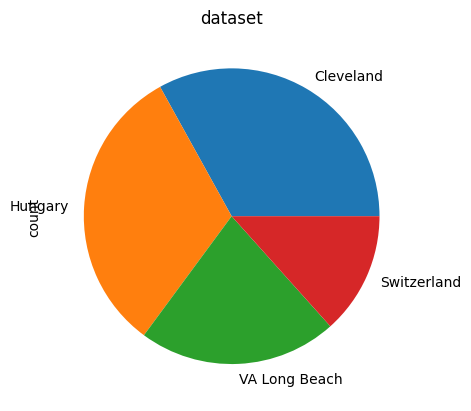

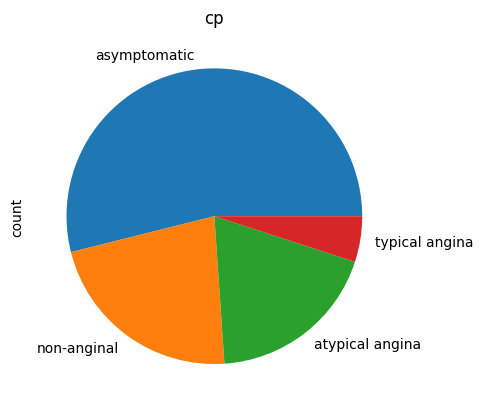

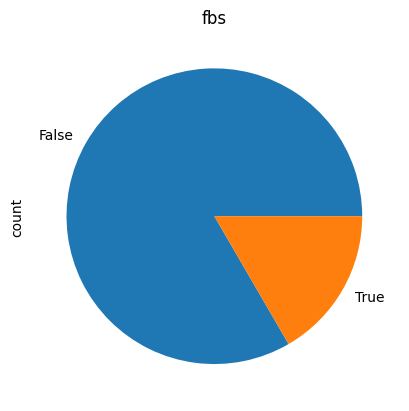

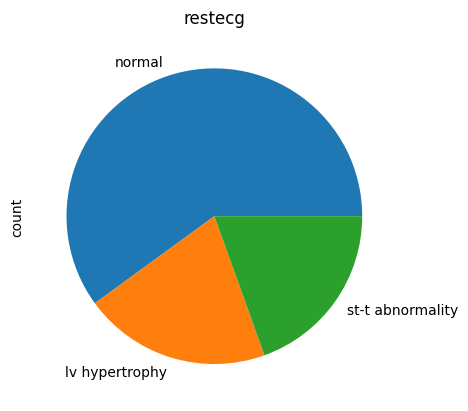

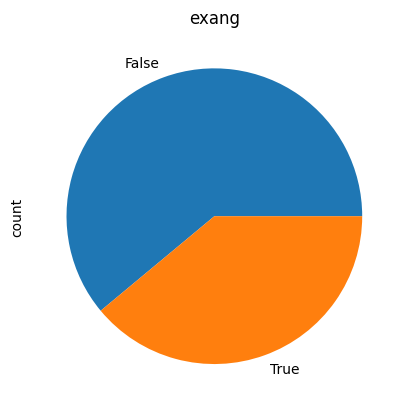

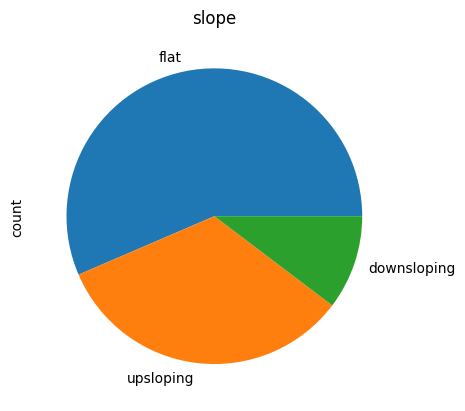

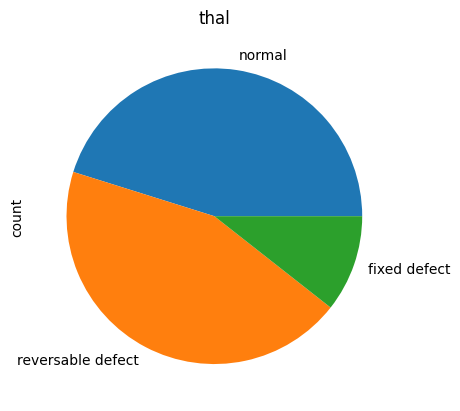

In [ ]:
for col in data2.select_dtypes("category").columns:
  plt.figure()
  data2[col].value_counts().plot.pie()
  plt.title(col)

- Dans ce dataset, on observe que plus de 75% des individus sont des hommes.
- Il n'y a pas le même nombre d'observations d'un hôpital à l'autre.
- Plus de la moitié des patients ne présentent pas de douleur toracique (**cp**).
- Plus de 75% des patients n'ont pas une glycélie à jeun (**fbs**)supérieure à 120mg/dl.
- Environ 55% des patients ont un electrocardiogramme au repos normal, n'ont pas d'angine déclanchée par l'effort et ont une pente du segment ST normale.
- Pour la plupart des individus (~ 45%), la valeur de la fréquence cardiaque maqimal est reversable defect, ce qui signifie qu'à l'effort le coeur est mal irrigué par le sang.

###Relation Target/Variable

Pour simplifier, puisque les catégories allant de 1 à 4 (qui regroupent les malades) ont peu d'observations par rapport à la catégorie 0, on va diviser la variable cible en deux catégories : malade/pas malade.

In [ ]:
data["num_bin"] = (data["num"] > 0).astype("int")
print(data[["num", "num_bin"]])

     num  num_bin
0      0        0
1      2        1
2      1        1
3      0        0
4      0        0
..   ...      ...
915    1        1
916    0        0
917    2        1
918    0        0
919    1        1

[920 rows x 2 columns]


In [ ]:
data_malade = data[data["num_bin"] == 1]
data_pas_malade = data[data["num_bin"] == 0]
print(data_pas_malade.head())
print(data_malade.head())

   id  age  trestbps   chol  thalch  oldpeak   ca  num  sex_Male  fbs_True  \
0   1   63     145.0  233.0   150.0      2.3  0.0    0         1         1   
3   4   37     130.0  250.0   187.0      3.5  0.0    0         1         0   
4   5   41     130.0  204.0   172.0      1.4  0.0    0         0         0   
5   6   56     120.0  236.0   178.0      0.8  0.0    0         1         0   
7   8   57     120.0  354.0   163.0      0.6  0.0    0         0         0   

   ...  cp_atypical angina  cp_non-anginal  cp_typical angina  restecg_normal  \
0  ...                   0               0                  1               0   
3  ...                   0               1                  0               1   
4  ...                   1               0                  0               0   
5  ...                   1               0                  0               1   
7  ...                   0               0                  0               1   

   restecg_st-t abnormality  slope_flat  slo

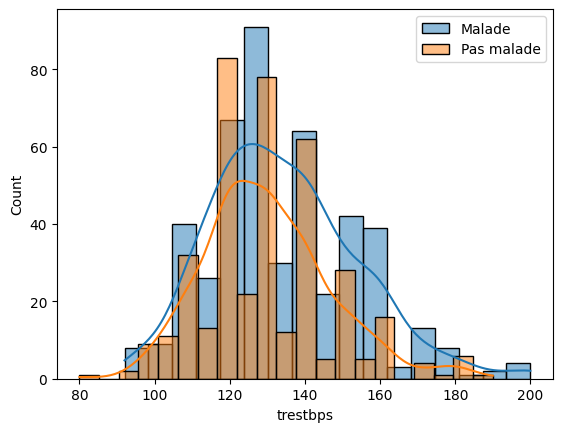

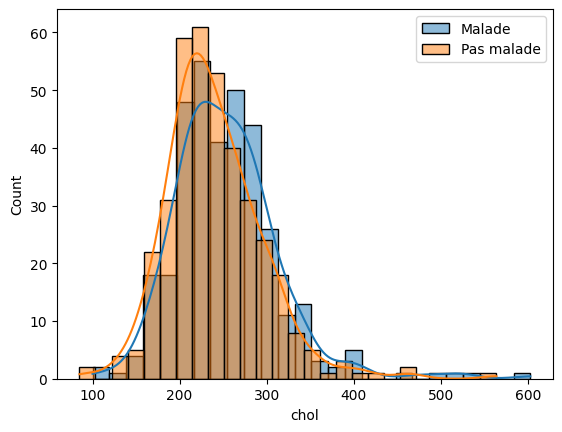

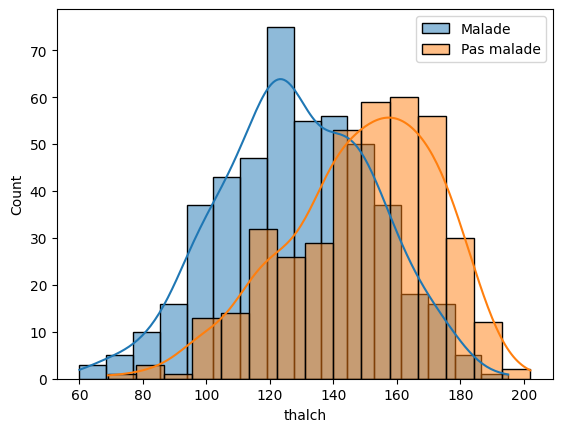

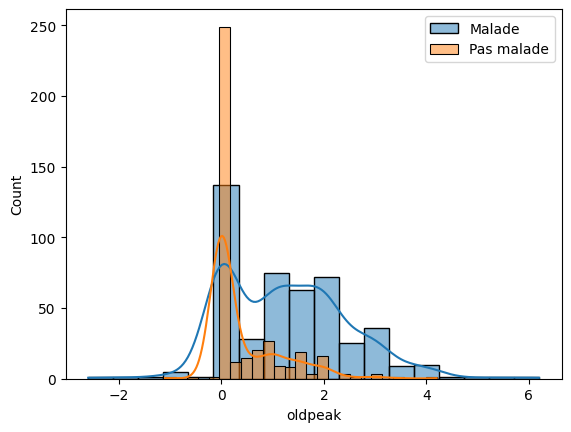

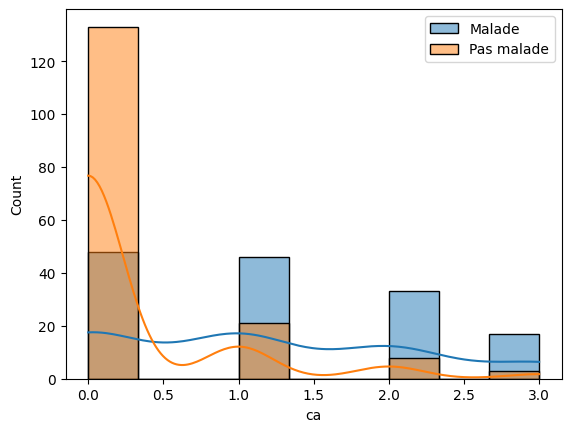

In [ ]:
for col in data.select_dtypes("float").columns:
  plt.figure()
  sns.histplot(data_malade[col], label = "Malade", kde = True)
  sns.histplot(data_pas_malade[col], label = "Pas malade", kde = True)
  plt.legend()


In [ ]:
print(f"Il y a {len(data_malade)} malades et {len(data_pas_malade)} individus pas malades dans le dataset.")

Il y a 509 malades et 411 individus pas malades dans le dataset.


- On observe une différence significative entre les malades et pas malades dans le graphe de densité pour la variable **thalach** (fréquence cardiaque maximale). La distribution des malades présente un pic à 120 bpm tandis que celle des non malades présente un pic à 160 bpm.
- La variable **oldpeak** (sous-décalage du segment ST) présente aussi une distribution différente entre les malades et ceux qui le sont pas. En effet, on peut observer que le pic qui s'étale entre 1 et 2.5 est beaucoup plus important pour les malades que pour les non malades, contrairement au pic à 0.
- Pour la variable **ca** (nombre de gros vaisseaux coronaires), on observe une différence significative entre les individus malades et pas malade au niveau de la valeurs 0: le nombre de personne saine n'ayant pas de gros vaisseaux coronaire est supérieur à celui des personnes malades.

In [ ]:
data2["num_bin"] = (data2["num"] >0 ).astype("int")
data2_malades = data2[data2["num_bin"] == 1]
data2_pas_malade = data2[data2["num_bin"] == 0]

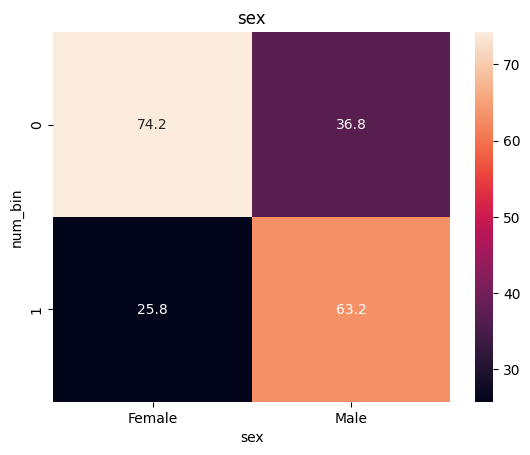

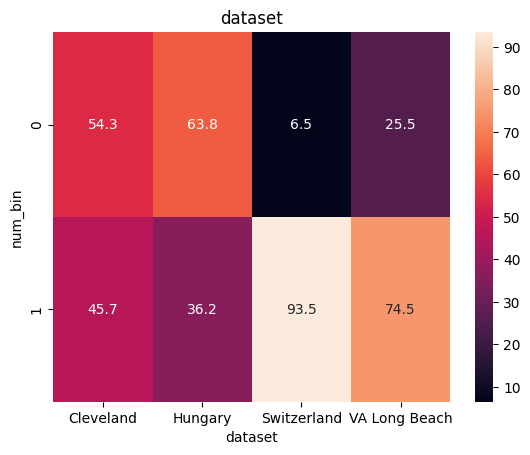

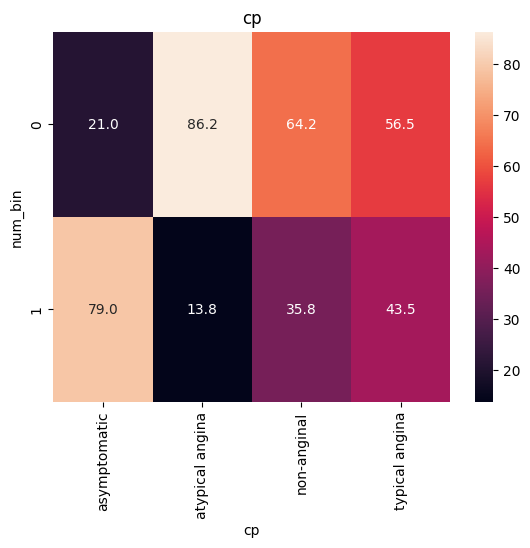

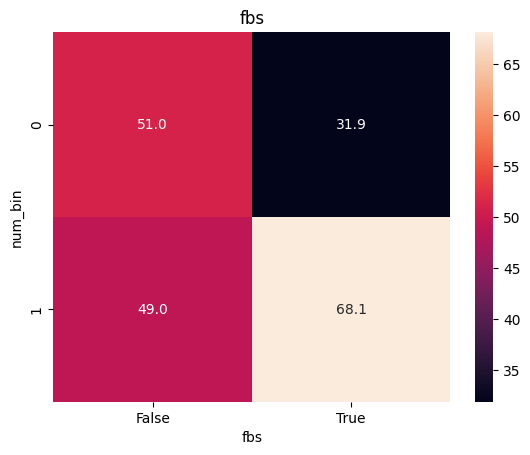

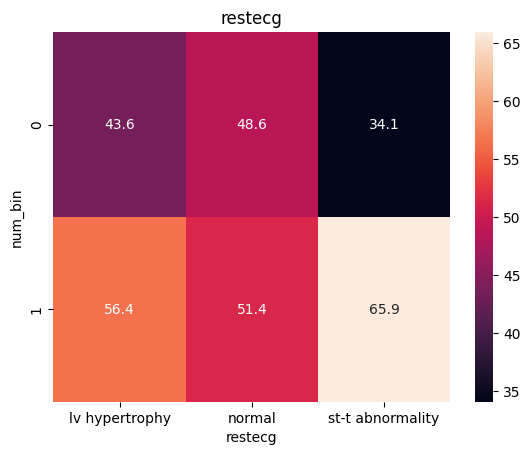

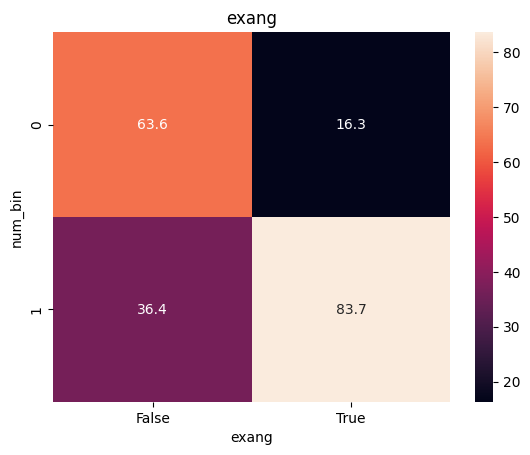

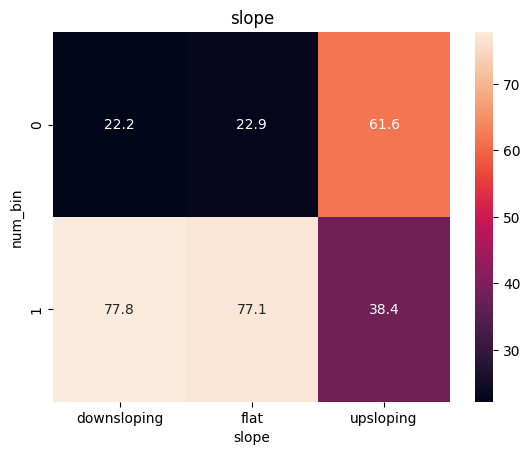

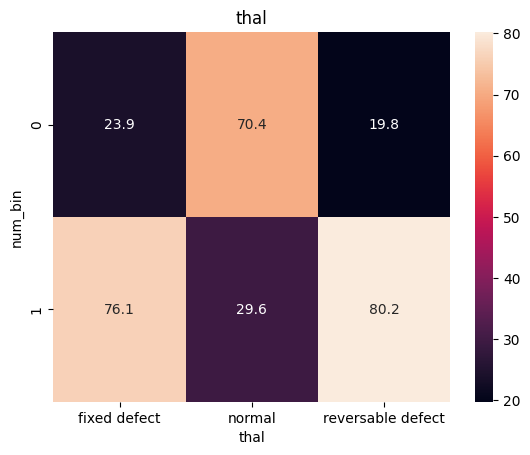

In [ ]:
for col in data2.select_dtypes("category").columns:
  plt.figure()
  sns.heatmap((pd.crosstab(data2["num_bin"], data2[col], normalize = "columns"))*100, annot = True, fmt = '.1f')
  plt.title(col)

- **sex** :
On observe que chez les femmes 74% des individus ne sont pas malades tandis que chez les hommes 63% sont malades.
- **Hôpital**: Il ya 4 catégories. On observe que les cohortes issues de la Suisse et VA Long Beach sont celles qui contiennent le moins de patients sains (6.5% et 25.5% respectivement).
- **type de douleur toracique** (vp): Il y a 4 catégories. 78% des personnes asymptomatiques sont malades et 86% des personnes dans la catégorie atypical angina  ne sont pas malade.
- **glycémie à jeun** (fbs): Il y a 2 catégories. 68% des personnes ayant une glycémie à jeun supérieure à 120mg/dL sont malades.
- **Electrocardiogramme au repos** - restecg :
Il y a 3 catégories. La catégorie où l'on observe une différence importante entre les malades et non malades est st-t abnormality : 65% des personnes dans cette catégorie sont malades.
-  **angine déclanchée à l'effort** - exang :
Il y a 2 catégories. On observe que 63% des individus qui n'ont pas d'angine déclanchée à l'effort ne sont pas malades et 83% des personnes ayant une angine déclanchée à l'effort sont malades
-  **pente du segment ST au pic de l’effort** - slope:
Il y a 3 catégories. La différence plus importante entre les malades et les non malades s'observe pour les catégorie downsloping et flat slope: pour ces deux catégories, 77% des individus sont malades.
- **résultat d’une scintigraphie myocardique au thallium, qui montre l’irrigation du muscle cardiaque** - thal :
Il y a 3 catégories. Pour chacune de ces catégories on observe une différence significative entre le pourcentage des personnes malades et celui des personnes pas malades :
  - normal: 70% ne sont pas malades
  - fixed defect : 76% sont malades
  - reversable defect : 80% sont malades